# External Validation: testing the 2024 models on BRFSS 2025

## 🗺️ Roadmap: read this first
**External validation** = testing the finished models on **completely new data** they have never seen, here the **next year's survey (2025)**.
The models are **frozen**: they are loaded from the files saved by notebook 2. There is **no retraining, no new threshold, no changes**. We only *apply* them.

```
 1 Load frozen models ─► 2 Load raw 2025 file ─► 3 Check 2025 codes match 2024 ─► 4 Decode exactly like 2024
                                                                                        │
 ┌──────────────────────────────────────────────────────────────────────────────────────┘
 ▼
 5 Create the 2 combined features ─► 6 Has the population changed? ─► 7 Rebuild 2024 test results (for comparison)
                                                                                        │
 ┌──────────────────────────────────────────────────────────────────────────────────────┘
 ▼
 8 Apply frozen models to 2025 ─► 9 Plots ─► 10 Fairness in 2025 ─► 11 New state (Tennessee) ─► 12 Conclusion
```

| Step | Question it answers |
|---|---|
| 1 | What exactly did notebook 2 save? |
| 2 | Is the 2025 file complete? (checked against the 2025 codebook) |
| 3 | Do the 2025 answer codes mean the same as in 2024? |
| 4–5 | Is the 2025 data prepared *identically* to the training data? |
| 6 | How different are 2025 respondents from 2024 respondents? |
| 7 | What were the original 2024 test scores? (recomputed, not copied) |
| 8–9 | **Do the models still work on 2025?** |
| 10 | Is it still fair across groups? |
| 11 | Does it work in a state that was **not in the 2024 training data at all**? |
| 12 | What does this mean for the paper? |

**Files needed in the same folder:** `LLCP2025.XPT` (unzipped CDC 2025 file), `BRFSS2024_access.csv`, and the `artifacts/` folder created by notebook 2.

# STEP 1 · Load the frozen models
> **What:** Load the two models saved by notebook 2 and show what is inside each file.  
> **Why here:** Everything else depends on the models. Loading them first also proves we are *not* training anything here.  
> **Result of this step:** the full model (37 features, threshold 0.71) and the short screener (11 inputs = 12 survey questions, threshold 0.21)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)

full = joblib.load("../models/brfss2024_cost_barrier_model.joblib")     # saved in notebook 2, Step 20
short = joblib.load("../models/brfss2024_short_screener.joblib")        # saved in notebook 2, Step 27

print("FULL MODEL  :", type(full["model"]).__name__, "| inputs:", len(full["features"]), "| threshold:", full["threshold"])
print("SHORT MODEL :", type(short["model"]).__name__, "| inputs:", len(short["features"]), "| threshold:", short["threshold"])
print("\nShort-screener questions:", short["features"])

FULL MODEL  : XGBClassifier | inputs: 37 | threshold: 0.71
SHORT MODEL : Pipeline | inputs: 11 | threshold: 0.22

Short-screener questions: ['income', 'insurance_type', 'age_group', 'employment', 'mental_unhealthy_days', 'general_health', 'home_ownership', 'physical_unhealthy_days', 'smoking_status', 'cognitive_difficulty', 'marital_status']


# STEP 2 · Load the raw 2025 CDC file
> **What:** Read the same 42 columns we used for 2024 from `LLCP2025.XPT`.  
> **Why here:** We need the raw data before we can check and decode it.  
> **Result of this step:** **356,158 rows × 42 columns**

In [2]:
keep = ['SEQNO','_STATE','_STSTR','_PSU','_LLCPWT','MEDCOST1',
        '_AGEG5YR','_SEX','_RACEGR3','_EDUCAG','_INCOMG1','EMPLOY1','MARITAL','RENTHOM1','VETERAN3','_CHLDCNT','_URBSTAT',
        'PRIMINS2','GENHLTH','_PHYS14D','_MENT14D','_BMI5CAT','_SMOKER3','_TOTINDA',
        'DIABETE4','_MICHD','CVDSTRK3','CHCCOPD3','ADDEPEV3','CHCKDNY2','HAVARTH4','_ASTHMS1','CHCOCNC1',
        'DEAF','BLIND','DECIDE','DIFFWALK','DIFFDRES','DIFFALON','PERSDOC3','CHECKUP1','_HLTHPL2']
raw = pd.concat([ch[keep] for ch in pd.read_sas("../data/LLCP2025.XPT", format="xport", chunksize=50000)], ignore_index=True)
print(raw.shape)
print("\nTarget counts (2025 codebook says: Yes 34,602 · No 320,314 · Don't know 945 · Refused 295):")
raw['MEDCOST1'].value_counts(dropna=False)

(356158, 42)

Target counts (2025 codebook says: Yes 34,602 · No 320,314 · Don't know 945 · Refused 295):


MEDCOST1
2.0    320314
1.0     34602
7.0       945
9.0       295
NaN         2
Name: count, dtype: int64

# STEP 3 · Check that the 2025 answer codes mean the same as in 2024
> **What:** Two checks. (a) We compared the **2024 and 2025 CDC codebooks**: all 38 variables used have the **same names, codes and meanings**. The only difference is a skip-instruction note in `DIABETE4` ("go to section 07.01" became "08.01"), which does not change any answer code.
> (b) Below, a data check: every code that appears in the 2025 file must be one our 2024 decoding knows, or a "Don't know / Refused" code.
> **Why here:** If a code changed meaning between years, the model would read 2025 answers wrongly. This must be checked *before* decoding.
> **Result of this step:** a table that should show **0 unknown codes** for every variable (age code 14 means "Don't know/Refused/Missing" in both codebooks).

In [3]:
# the code -> label maps used for 2024 (identical to notebook 0)
YN = {1: "Yes", 2: "No"}
MAPS = {
 '_URBSTAT': {1: "Urban", 2: "Rural"},
 '_AGEG5YR': {1:"18-24",2:"25-29",3:"30-34",4:"35-39",5:"40-44",6:"45-49",7:"50-54",8:"55-59",9:"60-64",10:"65-69",11:"70-74",12:"75-79",13:"80+"},
 '_SEX': {1: "Male", 2: "Female"},
 '_RACEGR3': {1:"White NH",2:"Black NH",3:"Other race NH",4:"Multiracial NH",5:"Hispanic"},
 '_EDUCAG': {1:"Less than high school",2:"High school graduate",3:"Some college/technical",4:"College graduate"},
 '_INCOMG1': {1:"<$15k",2:"$15k-<25k",3:"$25k-<35k",4:"$35k-<50k",5:"$50k-<100k",6:"$100k-<200k",7:"$200k+"},
 'EMPLOY1': {1:"Employed for wages",2:"Self-employed",3:"Out of work 1+ yr",4:"Out of work <1 yr",5:"Homemaker",6:"Student",7:"Retired",8:"Unable to work"},
 'MARITAL': {1:"Married",2:"Divorced",3:"Widowed",4:"Separated",5:"Never married",6:"Unmarried couple"},
 'RENTHOM1': {1:"Own",2:"Rent",3:"Other arrangement"},
 'VETERAN3': YN,
 '_CHLDCNT': {1:"0",2:"1",3:"2",4:"3",5:"4",6:"5+"},
 'PRIMINS2': {1:"Employer/union",2:"Self-purchased private",3:"Medicare",4:"Medicare",5:"Medicaid/CHIP/State",6:"Medicaid/CHIP/State",
              9:"Medicaid/CHIP/State",7:"Military/VA/IHS/Other gov",8:"Military/VA/IHS/Other gov",10:"Military/VA/IHS/Other gov",88:"No coverage"},
 'GENHLTH': {1:"Excellent",2:"Very good",3:"Good",4:"Fair",5:"Poor"},
 '_PHYS14D': {1:"0 days",2:"1-13 days",3:"14+ days"},
 '_MENT14D': {1:"0 days",2:"1-13 days",3:"14+ days"},
 '_BMI5CAT': {1:"Underweight",2:"Normal",3:"Overweight",4:"Obese"},
 '_SMOKER3': {1:"Current daily",2:"Current some days",3:"Former",4:"Never"},
 '_TOTINDA': {1:"Yes",2:"No"},
 'DIABETE4': {1:"Yes",2:"Gestational only",3:"No",4:"Prediabetes"},
 '_MICHD': {1:"Yes",2:"No"},
 'CVDSTRK3': YN, 'CHCCOPD3': YN, 'ADDEPEV3': YN, 'CHCKDNY2': YN, 'HAVARTH4': YN,
 '_ASTHMS1': {1:"Current",2:"Former",3:"Never"}, 'CHCOCNC1': YN,
 'DEAF': YN, 'BLIND': YN, 'DECIDE': YN, 'DIFFWALK': YN, 'DIFFDRES': YN, 'DIFFALON': YN,
}
DK_REFUSED = {7, 9, 77, 99}     # "Don't know" / "Refused" codes -> become "Unknown"
EXTRA_DK = {'_AGEG5YR': {14}}   # codebook (2024 and 2025): 14 = "Don't know/Refused/Missing"
check = []
for var, mp in MAPS.items():
    codes = set(raw[var].dropna().astype(int).unique())
    unknown_codes = sorted(codes - set(mp) - DK_REFUSED - EXTRA_DK.get(var, set()))
    check.append({'variable': var, 'codes found in 2025': len(codes), 'unknown codes': len(unknown_codes), 'which': unknown_codes})
check = pd.DataFrame(check)
print("Variables with unknown codes:", int((check['unknown codes'] > 0).sum()))
check

Variables with unknown codes: 0


,variable,codes found in 2025,unknown codes,which
0,_URBSTAT,2,0,[]
1,_AGEG5YR,14,0,[]
2,_SEX,2,0,[]
3,_RACEGR3,6,0,[]
4,_EDUCAG,5,0,[]
5,_INCOMG1,8,0,[]
6,EMPLOY1,9,0,[]
7,MARITAL,7,0,[]
8,RENTHOM1,5,0,[]
9,VETERAN3,4,0,[]


# STEP 4 · Decode 2025 exactly like 2024
> **What:** Turn the number codes into the same readable labels, with the same `Unknown` rule, the same region map and the same Medicaid-expansion list. Rows with no Yes/No answer for the target are removed.  
> **Why here:** Codes are confirmed (Step 3), so decoding is safe. The model only understands the labels it was trained on.  
> **Result of this step:** the 2025 analytic sample, same columns as `BRFSS2024_access.csv`

In [4]:
def decode(col, mapping):
    return raw[col].map(mapping).fillna("Unknown")

state_names = {1:'Alabama',2:'Alaska',4:'Arizona',5:'Arkansas',6:'California',8:'Colorado',9:'Connecticut',10:'Delaware',
 11:'District of Columbia',12:'Florida',13:'Georgia',15:'Hawaii',16:'Idaho',17:'Illinois',18:'Indiana',19:'Iowa',20:'Kansas',
 21:'Kentucky',22:'Louisiana',23:'Maine',24:'Maryland',25:'Massachusetts',26:'Michigan',27:'Minnesota',28:'Mississippi',
 29:'Missouri',30:'Montana',31:'Nebraska',32:'Nevada',33:'New Hampshire',34:'New Jersey',35:'New Mexico',36:'New York',
 37:'North Carolina',38:'North Dakota',39:'Ohio',40:'Oklahoma',41:'Oregon',42:'Pennsylvania',44:'Rhode Island',
 45:'South Carolina',46:'South Dakota',47:'Tennessee',48:'Texas',49:'Utah',50:'Vermont',51:'Virginia',53:'Washington',
 54:'West Virginia',55:'Wisconsin',56:'Wyoming',66:'Guam',72:'Puerto Rico',78:'Virgin Islands'}
region = {}
for f in [9,23,25,33,44,50,34,36,42]: region[f] = "Northeast"
for f in [17,18,26,39,55,19,20,27,29,31,38,46]: region[f] = "Midwest"
for f in [10,11,12,13,24,37,45,51,54,1,21,28,47,5,22,40,48]: region[f] = "South"
for f in [4,8,16,30,32,35,49,56,2,6,15,41,53]: region[f] = "West"
for f in [66,72,78]: region[f] = "Territory"
# KFF: the same 10 states had not adopted the ACA Medicaid expansion in 2025 as in 2024
non_expansion = {1,12,13,20,28,45,47,48,55,56}   # AL, FL, GA, KS, MS, SC, TN, TX, WI, WY

st = raw["_STATE"].astype(int)
d25 = pd.DataFrame({
    "could_not_afford_doctor": raw["MEDCOST1"].map(YN),
    "state": st.map(state_names),
    "census_region": st.map(region),
    "medicaid_expansion_state": np.where(st.isin([66,72,78]), "Territory", np.where(st.isin(non_expansion), "No", "Yes")),
    "urban_rural": decode("_URBSTAT", MAPS["_URBSTAT"]),
    "age_group": decode("_AGEG5YR", MAPS["_AGEG5YR"]), "sex": decode("_SEX", MAPS["_SEX"]),
    "race_ethnicity": decode("_RACEGR3", MAPS["_RACEGR3"]), "education": decode("_EDUCAG", MAPS["_EDUCAG"]),
    "income": decode("_INCOMG1", MAPS["_INCOMG1"]), "employment": decode("EMPLOY1", MAPS["EMPLOY1"]),
    "marital_status": decode("MARITAL", MAPS["MARITAL"]), "home_ownership": decode("RENTHOM1", MAPS["RENTHOM1"]),
    "veteran": decode("VETERAN3", YN), "children_in_household": decode("_CHLDCNT", MAPS["_CHLDCNT"]),
    "insurance_type": decode("PRIMINS2", MAPS["PRIMINS2"]), "general_health": decode("GENHLTH", MAPS["GENHLTH"]),
    "physical_unhealthy_days": decode("_PHYS14D", MAPS["_PHYS14D"]), "mental_unhealthy_days": decode("_MENT14D", MAPS["_MENT14D"]),
    "bmi_category": decode("_BMI5CAT", MAPS["_BMI5CAT"]), "smoking_status": decode("_SMOKER3", MAPS["_SMOKER3"]),
    "physical_activity": decode("_TOTINDA", MAPS["_TOTINDA"]),
    "diabetes": decode("DIABETE4", MAPS["DIABETE4"]), "heart_disease": decode("_MICHD", MAPS["_MICHD"]),
    "stroke": decode("CVDSTRK3", YN), "copd": decode("CHCCOPD3", YN), "depression": decode("ADDEPEV3", YN),
    "kidney_disease": decode("CHCKDNY2", YN), "arthritis": decode("HAVARTH4", YN),
    "asthma": decode("_ASTHMS1", MAPS["_ASTHMS1"]), "cancer_non_skin": decode("CHCOCNC1", YN),
    "hearing_difficulty": decode("DEAF", YN), "vision_difficulty": decode("BLIND", YN), "cognitive_difficulty": decode("DECIDE", YN),
    "mobility_difficulty": decode("DIFFWALK", YN), "selfcare_difficulty": decode("DIFFDRES", YN),
    "independent_living_difficulty": decode("DIFFALON", YN),
    "survey_weight": raw["_LLCPWT"],
    "strata": raw["_STSTR"], "psu": raw["_PSU"],
})
before = len(d25)
d25 = d25[d25["could_not_afford_doctor"].notna()].reset_index(drop=True)
w25 = d25["survey_weight"].values
print(f"Removed {before - len(d25):,} rows without a Yes/No target -> 2025 analytic sample n = {len(d25):,}")
print("Weighted % Yes (2025):", round(100 * np.average(d25.could_not_afford_doctor == 'Yes', weights=w25), 2))
d25.head()

Removed 1,242 rows without a Yes/No target -> 2025 analytic sample n = 354,916
Weighted % Yes (2025): 12.74


,could_not_afford_doctor,state,census_region,medicaid_expansion_state,urban_rural,age_group,sex,race_ethnicity,education,income,employment,marital_status,home_ownership,veteran,children_in_household,insurance_type,general_health,physical_unhealthy_days,mental_unhealthy_days,bmi_category,smoking_status,physical_activity,diabetes,heart_disease,stroke,copd,depression,kidney_disease,arthritis,asthma,cancer_non_skin,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty,survey_weight,strata,psu
0,No,Alabama,South,No,Urban,70-74,Female,Black NH,Some college/technical,$35k-<50k,Retired,Divorced,Rent,No,0,Medicare,Good,1-13 days,1-13 days,Obese,Never,Yes,No,No,No,No,No,No,Yes,Never,No,No,No,No,Yes,No,No,135.411848,11011.0,2.025000e+09
1,No,Alabama,South,No,Urban,80+,Female,White NH,Some college/technical,Unknown,Retired,Widowed,Own,No,0,Military/VA/IHS/Other gov,Good,0 days,0 days,Normal,Never,Yes,Yes,No,No,No,No,No,No,Never,Yes,No,Yes,No,Yes,No,Yes,190.376819,11011.0,2.025000e+09
2,Yes,Alabama,South,No,Urban,65-69,Female,White NH,High school graduate,Unknown,Homemaker,Married,Own,No,0,Medicare,Fair,0 days,0 days,Obese,Never,No,Yes,No,No,No,No,Unknown,Yes,Never,No,No,No,No,No,No,No,471.630521,11011.0,2.025000e+09
3,No,Alabama,South,No,Urban,80+,Male,White NH,High school graduate,Unknown,Retired,Married,Own,No,0,Medicare,Fair,Unknown,0 days,Overweight,Never,No,Yes,No,No,No,No,No,Yes,Never,Yes,Yes,No,Yes,Yes,No,Yes,473.720063,11011.0,2.025000e+09
4,No,Alabama,South,No,Urban,60-64,Male,White NH,Some college/technical,$50k-<100k,Retired,Married,Own,No,0,Employer/union,Good,0 days,1-13 days,Overweight,Never,Yes,No,No,No,Yes,Yes,No,Yes,Current,No,No,No,No,Yes,No,No,662.064923,11011.0,2.025000e+09


In [5]:
# which states differ between the 2024 training data and 2025?
d24 = pd.read_csv("../data/BRFSS2024_access.csv", dtype={"children_in_household": str})
s24, s25 = set(d24.state.unique()), set(d25.state.unique())
print("In 2025 but NOT in 2024 (never seen in training):", sorted(s25 - s24))
print("In 2024 but NOT in 2025:", sorted(s24 - s25))

In 2025 but NOT in 2024 (never seen in training): ['Tennessee']
In 2024 but NOT in 2025: ['California', 'Mississippi', 'Nevada', 'Virgin Islands']


# STEP 5 · Create the 2 combined features
> **What:** Count disabilities (6 columns) and chronic conditions (9 columns) exactly as in notebook 2, Step 3.  
> **Why here:** The saved files contain the *encoding* and the model, but not this counting step, so we repeat it.  
> **Result of this step:** 2025 data with the same 37 input features the models expect

In [6]:
chronic = {'diabetes':'Yes','heart_disease':'Yes','stroke':'Yes','copd':'Yes','depression':'Yes',
           'kidney_disease':'Yes','arthritis':'Yes','asthma':'Current','cancer_non_skin':'Yes'}
dis_cols = ['hearing_difficulty','vision_difficulty','cognitive_difficulty','mobility_difficulty',
            'selfcare_difficulty','independent_living_difficulty']
def add_counts(d):
    d = d.copy()
    d['n_chronic_conditions'] = sum((d[c] == v).astype(int) for c, v in chronic.items())
    d['n_disabilities'] = (d[dis_cols] == 'Yes').sum(axis=1)
    return d
d25 = add_counts(d25)
y25 = (d25['could_not_afford_doctor'] == 'Yes').astype(int).values
missing_inputs = [f for f in full["features"] if f not in d25.columns]
print("Inputs the model needs but 2025 lacks:", missing_inputs)
print("2025 data shape:", d25.shape)
d25[dis_cols + ['n_disabilities']].head()

Inputs the model needs but 2025 lacks: []
2025 data shape: (354916, 42)


,hearing_difficulty,vision_difficulty,cognitive_difficulty,mobility_difficulty,selfcare_difficulty,independent_living_difficulty,n_disabilities
0,No,No,No,Yes,No,No,1
1,No,Yes,No,Yes,No,Yes,3
2,No,No,No,No,No,No,0
3,Yes,No,Yes,Yes,No,Yes,4
4,No,No,No,Yes,No,No,1


# STEP 6 · Has the population changed between 2024 and 2025?
> **What:** Compare the weighted share of key answers in 2024 and 2025.  
> **Why here:** If 2025 respondents differ, scores can change for reasons other than the model. We need to know this before reading the results.  
> **Result of this step:** a 2024-vs-2025 comparison table

In [7]:
def wshare(d, col, w):
    return (d.groupby(col)[w].sum() / d[w].sum() * 100)
rows = []
for col in ['could_not_afford_doctor', 'insurance_type', 'income', 'age_group', 'employment', 'mental_unhealthy_days']:
    a = wshare(d24, col, 'survey_weight'); b = wshare(d25, col, 'survey_weight')
    t = pd.DataFrame({'2024 %': a, '2025 %': b}).fillna(0); t['change'] = t['2025 %'] - t['2024 %']
    t.index = [f'{col} = {i}' for i in t.index]; rows.append(t)
shift = pd.concat(rows).round(2)
shift.loc[shift['change'].abs().sort_values(ascending=False).index].head(15)

,2024 %,2025 %,change
mental_unhealthy_days = 0 days,55.52,54.60,-0.92
employment = Retired,20.47,21.24,0.77
mental_unhealthy_days = 14+ days,15.20,15.81,0.61
employment = Employed for wages,46.14,45.69,-0.45
income = $100k-<200k,18.11,18.54,0.43
could_not_afford_doctor = No,87.67,87.26,-0.40
could_not_afford_doctor = Yes,12.33,12.74,0.40
insurance_type = Unknown,5.21,5.55,0.34
income = $15k-<25k,7.18,6.84,-0.34
employment = Self-employed,9.45,9.14,-0.31


# STEP 7 · Rebuild the 2024 test results (for a fair comparison)
> **What:** Recreate the exact 2024 test set (same split, same seed as notebook 2) and score both models on it.  
> **Why here:** We compare 2025 against 2024 using numbers **recomputed here**, not copied, so the comparison is verifiable.  
> **Result of this step:** the 2024 test scores: they must match notebook 2 (0.845 full, 0.839 short)

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score, f1_score,
                             accuracy_score, brier_score_loss, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.calibration import CalibrationDisplay

d24c = add_counts(d24)
X24 = d24c[full["features"]]
y24 = (d24c['could_not_afford_doctor'] == 'Yes').astype(int).values
_, X24_test, _, y24_test, _, w24_test = train_test_split(X24, y24, d24c['survey_weight'].values,
                                                          test_size=0.2, random_state=42, stratify=y24)

def score_full(X):  return full["model"].predict_proba(full["preprocessor"].transform(X[full["features"]]))[:, 1]
def score_short(X): return short["model"].predict_proba(X[short["features"]])[:, 1]

p24_full, p24_short = score_full(X24_test), score_short(X24_test)
print("2024 test (n = {:,}): full ROC-AUC {:.4f} | short ROC-AUC {:.4f}".format(
      len(y24_test), roc_auc_score(y24_test, p24_full), roc_auc_score(y24_test, p24_short)))

2024 test (n = 91,200): full ROC-AUC 0.8450 | short ROC-AUC 0.8394


# STEP 8 · Apply the frozen models to 2025: the external test
> **What:** Score every 2025 person with both models, using the saved thresholds, and compare with 2024.  
> **Why here:** Data is prepared and checked (Steps 2–6), and the 2024 reference exists (Step 7).  
> **Result of this step:** **the main result**: 2025 vs 2024 performance

In [9]:
p25_full, p25_short = score_full(d25), score_short(d25)

def scorecard(y, p, th, w=None):
    yp = (p >= th).astype(int)
    return {'n': len(y), '% Yes': 100 * (np.average(y, weights=w) if w is not None else y.mean()),
            'ROC-AUC': roc_auc_score(y, p, sample_weight=w), 'PR-AUC': average_precision_score(y, p, sample_weight=w),
            'Accuracy': accuracy_score(y, yp, sample_weight=w), 'Precision (Yes)': precision_score(y, yp, sample_weight=w),
            'Recall (Yes)': recall_score(y, yp, sample_weight=w), 'F1 (Yes)': f1_score(y, yp, sample_weight=w),
            'Brier': brier_score_loss(y, p, sample_weight=w), 'Mean predicted risk %': 100 * (np.average(p, weights=w) if w is not None else p.mean())}

results = pd.DataFrame({
    'Full model · 2024 test':           scorecard(y24_test, p24_full, full["threshold"]),
    'Full model · 2025 (external)':     scorecard(y25, p25_full, full["threshold"]),
    'Short screener · 2024 test':       scorecard(y24_test, p24_short, short["threshold"]),
    'Short screener · 2025 (external)': scorecard(y25, p25_short, short["threshold"]),
}).T
results_w = pd.DataFrame({
    'Full model · 2024 test (weighted)':           scorecard(y24_test, p24_full, full["threshold"], w24_test),
    'Full model · 2025 (weighted)':                scorecard(y25, p25_full, full["threshold"], w25),
    'Short screener · 2024 test (weighted)':       scorecard(y24_test, p24_short, short["threshold"], w24_test),
    'Short screener · 2025 (weighted)':            scorecard(y25, p25_short, short["threshold"], w25),
}).T
print("UNWEIGHTED (sample)"); display(results.round(4))
print("SURVEY-WEIGHTED (U.S. adults)"); display(results_w.round(4))

UNWEIGHTED (sample)


,n,% Yes,ROC-AUC,PR-AUC,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Brier,Mean predicted risk %
Full model · 2024 test,91200.0,9.5099,0.8450,0.4184,0.8668,0.3614,0.5227,0.4273,0.1625,35.6961
Full model · 2025 (external),354916.0,9.7493,0.8438,0.4224,0.8691,0.3736,0.5065,0.4300,0.1583,35.0365
Short screener · 2024 test,91200.0,9.5099,0.8394,0.4072,0.8736,0.3726,0.4806,0.4197,0.0696,9.4953
Short screener · 2025 (external),354916.0,9.7493,0.8379,0.4123,0.8738,0.3805,0.4682,0.4198,0.0711,9.2732


SURVEY-WEIGHTED (U.S. adults)


,n,% Yes,ROC-AUC,PR-AUC,Accuracy,Precision (Yes),Recall (Yes),F1 (Yes),Brier,Mean predicted risk %
Full model · 2024 test (weighted),91200.0,12.0097,0.8327,0.4550,0.8321,0.3720,0.5782,0.4527,0.1967,41.9737
Full model · 2025 (weighted),354916.0,12.7381,0.8255,0.4551,0.8339,0.3911,0.5457,0.4557,0.1913,41.2396
Short screener · 2024 test (weighted),91200.0,12.0097,0.8272,0.4444,0.8488,0.4012,0.5261,0.4552,0.0846,11.4932
Short screener · 2025 (weighted),354916.0,12.7381,0.8183,0.4455,0.8433,0.4049,0.4901,0.4435,0.0899,11.2610


In [ ]:
# How confident are we? 95% design-based bootstrap confidence interval for the change in ROC-AUC (2025 minus 2024)
# Design-based bootstrap: resample primary sampling units (PSUs) with replacement WITHIN each stratum.
# (In the BRFSS public file every respondent is its own PSU, so this is a stratified bootstrap of respondents.)
def design_sampler(strata, psu, rng):
    cl, cl_of_row = np.unique(np.stack([strata, psu], 1), axis=0, return_inverse=True)
    cl_of_row = cl_of_row.ravel()
    row_order = np.argsort(cl_of_row, kind='stable')
    cl_size = np.bincount(cl_of_row, minlength=len(cl)); cl_start = np.r_[0, np.cumsum(cl_size)[:-1]]
    st_order = np.argsort(cl[:, 0], kind='stable'); st_sorted = cl[st_order, 0]
    st_start = np.r_[0, np.flatnonzero(st_sorted[1:] != st_sorted[:-1]) + 1]
    st_size = np.diff(np.r_[st_start, len(st_sorted)])
    g_start, g_size = np.repeat(st_start, st_size), np.repeat(st_size, st_size)
    def draw():
        chosen = st_order[g_start + (rng.random_sample(len(st_order)) * g_size).astype(int)]
        lens = cl_size[chosen]; offs = np.repeat(cl_start[chosen] - np.r_[0, np.cumsum(lens)[:-1]], lens)
        return row_order[offs + np.arange(lens.sum())]
    return draw

rng = np.random.RandomState(42)
_, te_idx = train_test_split(np.arange(len(d24c)), test_size=0.2, random_state=42, stratify=y24)
assert np.array_equal(y24[te_idx], y24_test)          # same test rows as above
draw24 = design_sampler(d24c['strata'].values[te_idx], d24c['psu'].values[te_idx], rng)
draw25 = design_sampler(d25['strata'].values, d25['psu'].values, rng)
def boot_auc(y, p, draw, B=200):
    return np.array([roc_auc_score(y[i], p[i]) for i in (draw() for _ in range(B))])
ci = {}
for name, (pa, pb) in {'Full': (p24_full, p25_full), 'Short': (p24_short, p25_short)}.items():
    a, b = boot_auc(y24_test, pa, draw24), boot_auc(y25, pb, draw25)
    ci[name] = {'2024 AUC': roc_auc_score(y24_test, pa), '2025 AUC': roc_auc_score(y25, pb),
                '2025 95% CI': f"{np.percentile(b, 2.5):.3f} – {np.percentile(b, 97.5):.3f}",
                'change': roc_auc_score(y25, pb) - roc_auc_score(y24_test, pa),
                'change 95% CI': f"{np.percentile(b - a, 2.5):+.3f} to {np.percentile(b - a, 97.5):+.3f}"}
pd.DataFrame(ci).T.round(4)

**Main result: the models hold up on new data.**

| | 2024 test (91,200) | **2025 external (354,916)** | Change (95% CI) |
|---|---|---|---|
| Full model ROC-AUC | 0.845 | **0.844** | −0.001 (−0.006 to +0.003) |
| Short screener ROC-AUC | 0.839 | **0.838** | −0.002 (−0.006 to +0.002) |
| Full model PR-AUC | 0.418 | **0.422** | slightly higher |
| Short screener PR-AUC | 0.407 | **0.412** | slightly higher |
| Short screener Brier (calibration) | 0.070 | **0.071** | stable |

* The confidence intervals for the change **include zero**: there is **no measurable loss** of performance a year later.
* **Survey-weighted** ROC-AUC drops slightly (full 0.833 → 0.825; short 0.827 → 0.818). Still a good, consistent result, and worth reporting alongside the unweighted numbers.
* **Calibration still holds.** The short screener predicts an average risk of 9.3% against a true rate of 9.7% (unweighted), so its percentages stay trustworthy.
* **Population shift was small** (Step 6): weighted prevalence 12.33% → 12.74%, and no key answer category moved more than about 1 percentage point. 2025 is a fair, not artificially easy, test: it also has different states (Tennessee added; California, Mississippi, Nevada and the Virgin Islands absent).

# STEP 9 · Plots: 2024 vs 2025
> **What:** ROC, precision–recall and calibration curves for both models in both years, plus the 2025 confusion matrices.  
> **Why here:** Numbers (Step 8) show *how much*; plots show *where* any change happens.  
> **Result of this step:** 4 + 2 charts

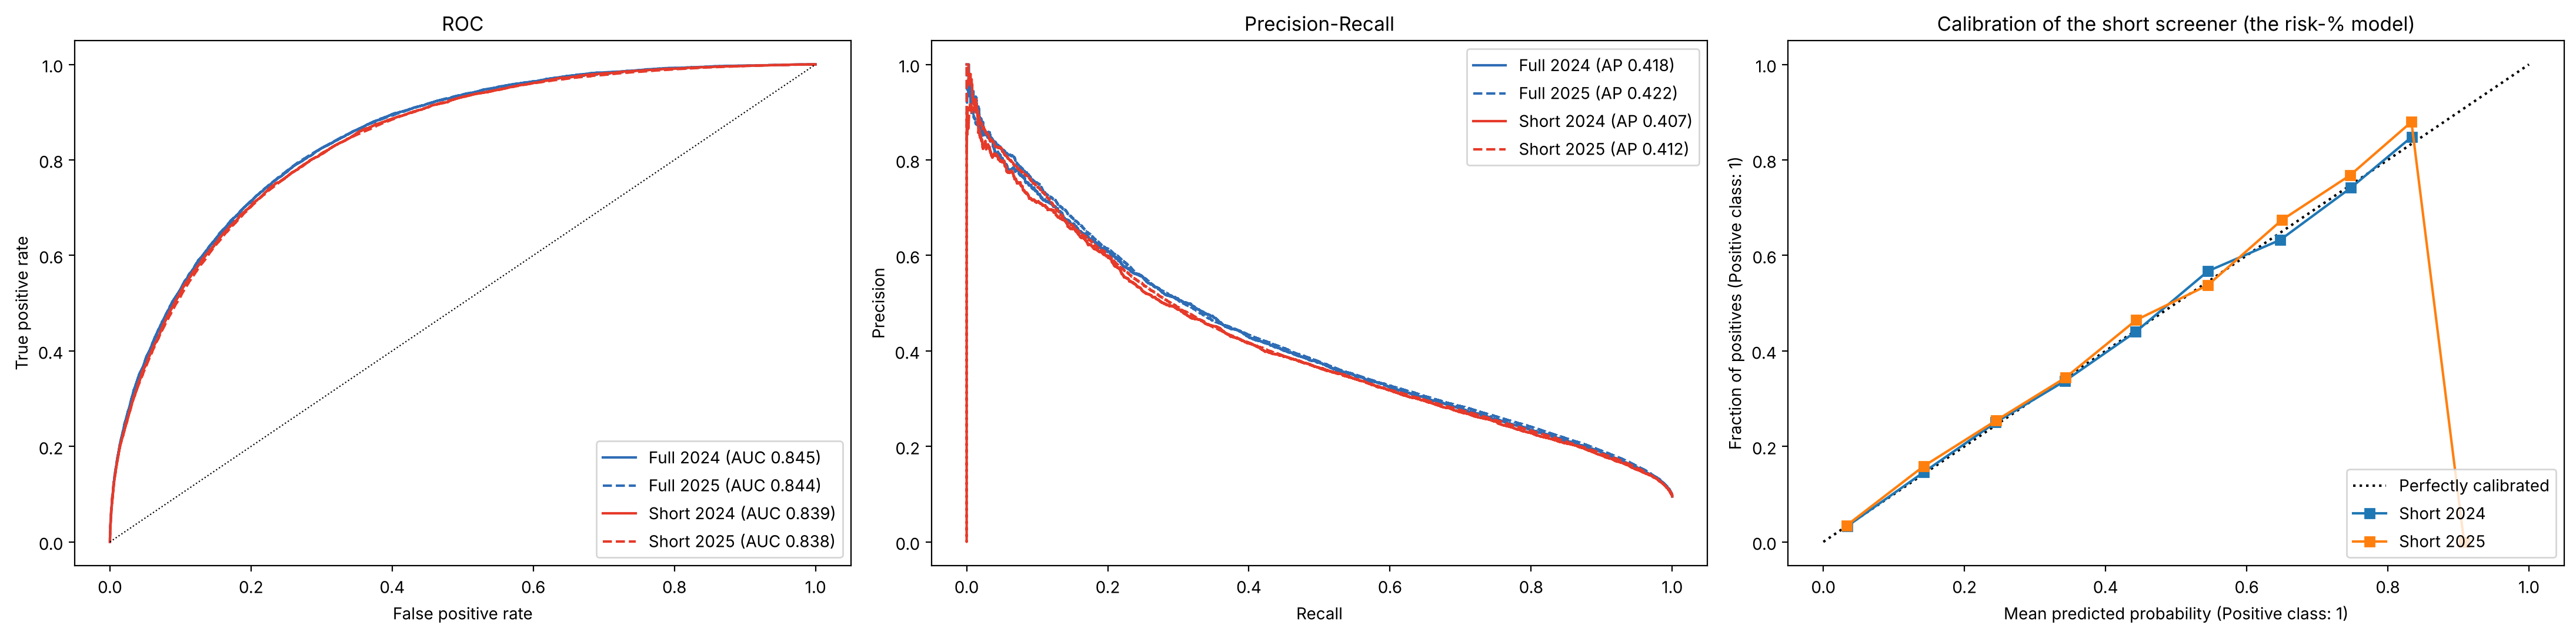

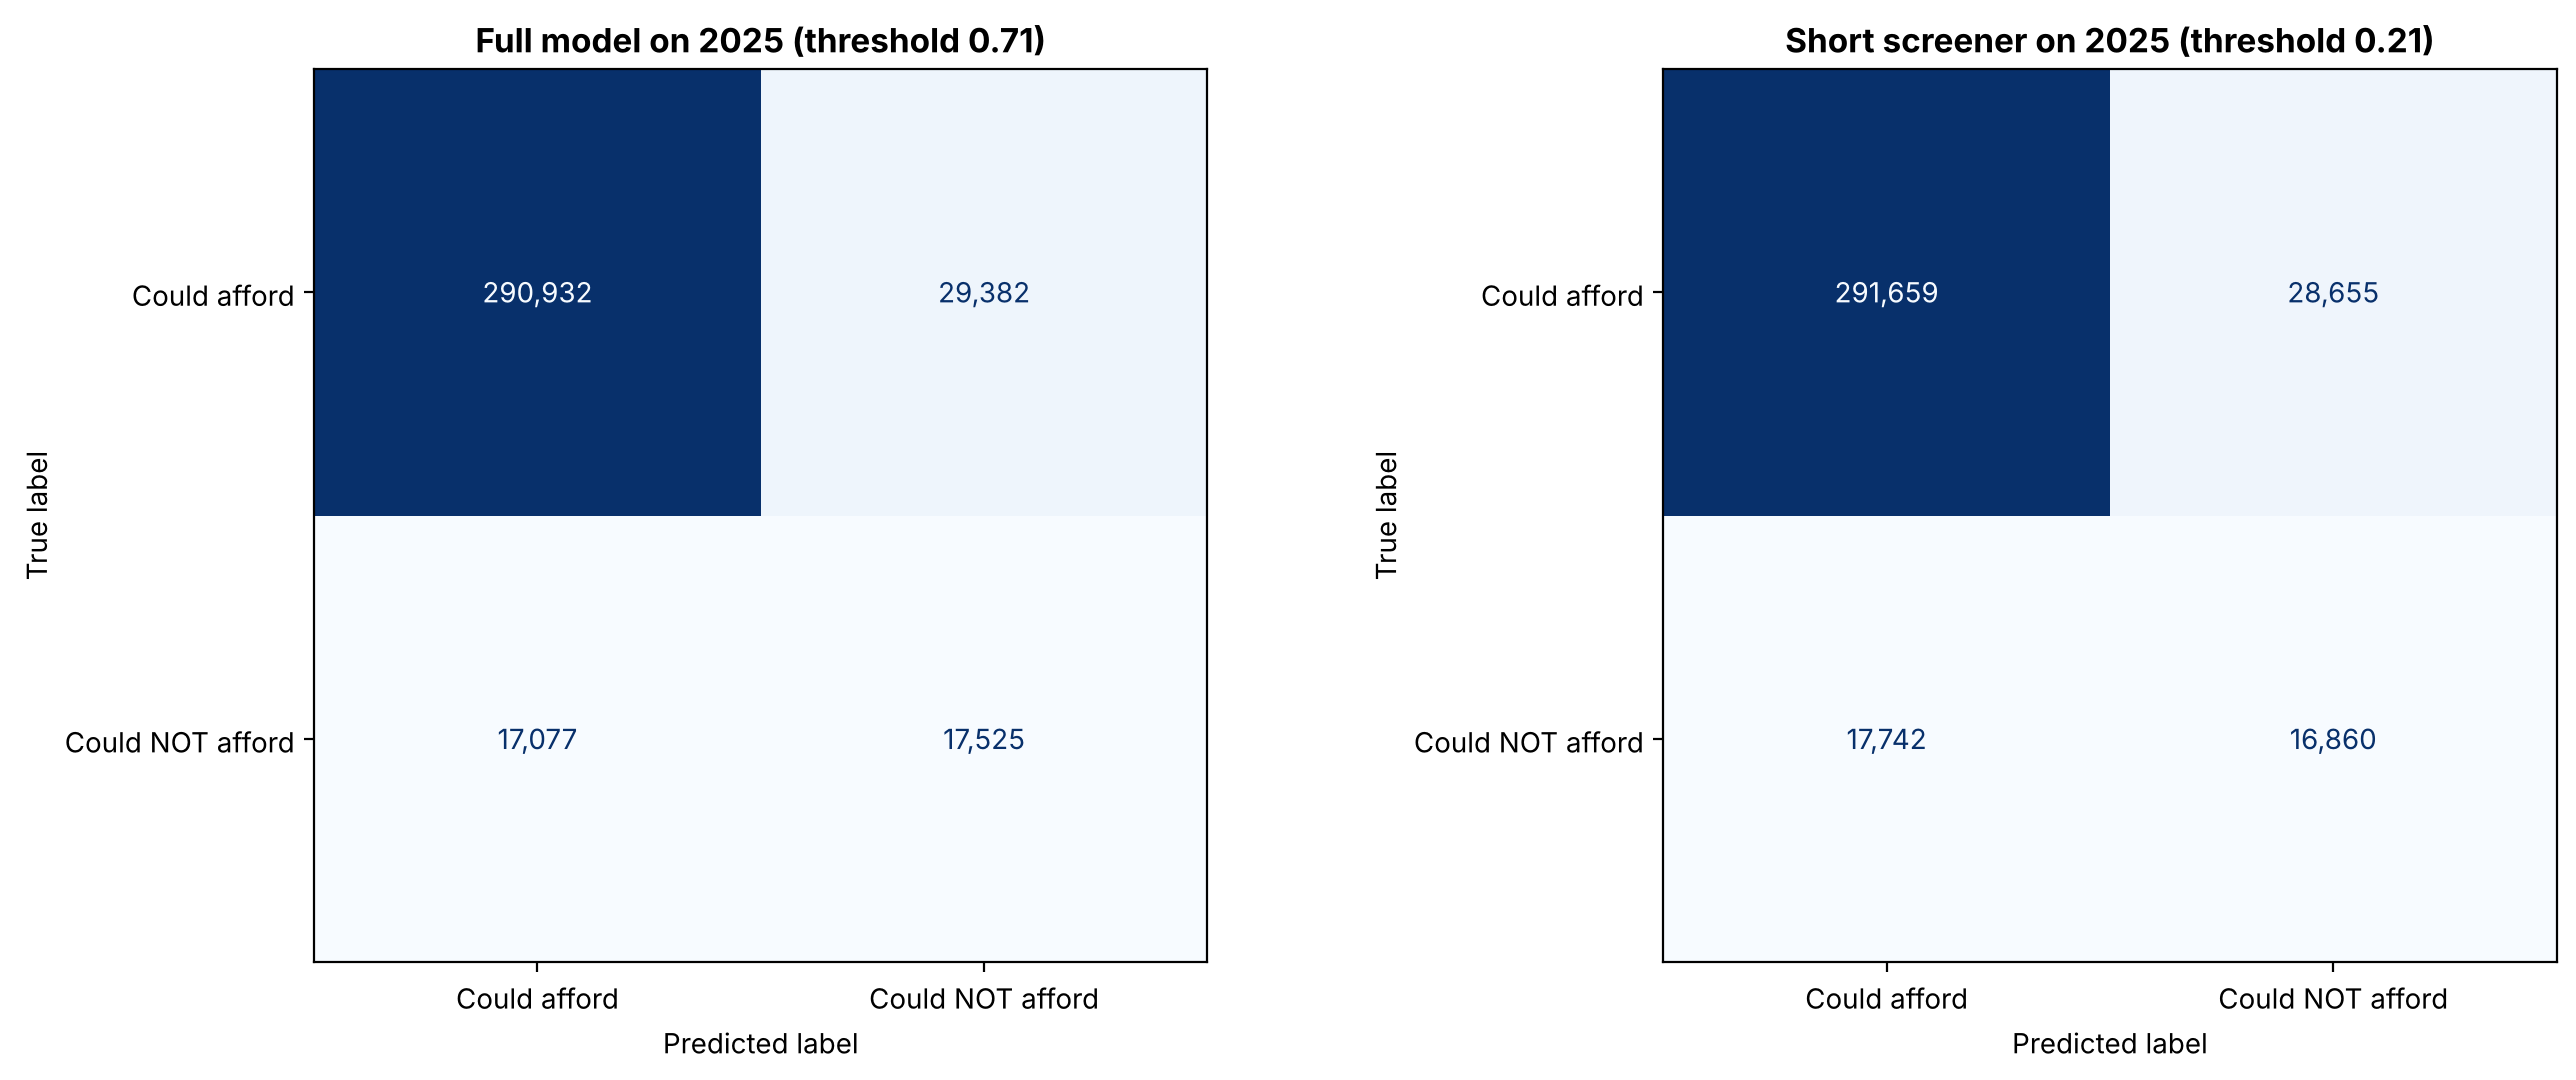

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve
fig, ax = plt.subplots(1, 3, figsize=(22, 5.5))
for p, y, lab, ls, col in [(p24_full, y24_test, 'Full 2024', '-', '#2f6db5'), (p25_full, y25, 'Full 2025', '--', '#2f6db5'),
                           (p24_short, y24_test, 'Short 2024', '-', '#e63a2a'), (p25_short, y25, 'Short 2025', '--', '#e63a2a')]:
    fpr, tpr, _ = roc_curve(y, p); ax[0].plot(fpr, tpr, ls=ls, c=col, label=f'{lab} (AUC {roc_auc_score(y, p):.3f})')
    pr, rc, _ = precision_recall_curve(y, p); ax[1].plot(rc, pr, ls=ls, c=col, label=f'{lab} (AP {average_precision_score(y, p):.3f})')
ax[0].plot([0,1],[0,1],'k:',lw=.8); ax[0].set_title('ROC'); ax[0].set_xlabel('False positive rate'); ax[0].set_ylabel('True positive rate'); ax[0].legend()
ax[1].set_title('Precision-Recall'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend()
CalibrationDisplay.from_predictions(y24_test, p24_short, n_bins=10, ax=ax[2], name='Short 2024')
CalibrationDisplay.from_predictions(y25, p25_short, n_bins=10, ax=ax[2], name='Short 2025')
ax[2].set_title('Calibration of the short screener (the risk-% model)')
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for a, (p, th, t) in zip(ax, [(p25_full, full["threshold"], 'Full model'), (p25_short, short["threshold"], 'Short screener')]):
    ConfusionMatrixDisplay(confusion_matrix(y25, (p >= th).astype(int)), display_labels=['Could afford', 'Could NOT afford']) \
        .plot(ax=a, colorbar=False, cmap='Blues', values_format=',')
    a.set_title(f'{t} on 2025 (threshold {th})', weight='bold')
plt.tight_layout(); plt.show()

# STEP 10 · Fairness in 2025
> **What:** ROC-AUC and recall by group in 2025, for both models.  
> **Why here:** Overall results can hide group differences, and the 2024 gaps (Steps 18 and 25 of notebook 2) must be re-checked on new data.  
> **Result of this step:** a subgroup table for 2025

In [ ]:
age_band = {'18-24':'18-34','25-29':'18-34','30-34':'18-34','35-39':'35-49','40-44':'35-49','45-49':'35-49',
            '50-54':'50-64','55-59':'50-64','60-64':'50-64','65-69':'65+','70-74':'65+','75-79':'65+','80+':'65+'}
G = d25.assign(age_band=d25['age_group'].map(age_band).fillna('Unknown'), y=y25, w=w25,
               pf=p25_full, ps=p25_short,
               yf=(p25_full >= full["threshold"]).astype(int), ys=(p25_short >= short["threshold"]).astype(int))
rows = []
for col in ['race_ethnicity', 'income', 'urban_rural', 'sex', 'age_band', 'insurance_type', 'medicaid_expansion_state']:
    for g, d in G.groupby(col):
        if g == 'Unknown' or d.y.sum() < 30: continue
        rows.append({'group': f'{col} = {g}', 'n': len(d), '% Yes (weighted)': 100 * np.average(d.y, weights=d.w),
                     'Full AUC': roc_auc_score(d.y, d.pf, sample_weight=d.w), 'Short AUC': roc_auc_score(d.y, d.ps, sample_weight=d.w),
                     'Full recall': recall_score(d.y, d.yf, sample_weight=d.w), 'Short recall': recall_score(d.y, d.ys, sample_weight=d.w)})
fair25 = pd.DataFrame(rows).set_index('group')
fair25.round(3)

,n,% Yes (weighted),Full AUC,Short AUC,Full recall,Short recall
group,,,,,,
race_ethnicity = Black NH,25926,15.221,0.779,0.774,0.516,0.461
race_ethnicity = Hispanic,34940,19.772,0.781,0.773,0.691,0.596
race_ethnicity = Multiracial NH,8698,18.556,0.791,0.785,0.618,0.562
race_ethnicity = Other race NH,19759,12.640,0.792,0.778,0.458,0.406
race_ethnicity = White NH,257407,9.750,0.844,0.838,0.475,0.482
income = $100k-<200k,64511,5.974,0.794,0.783,0.178,0.155
income = $15k-<25k,25428,22.837,0.759,0.748,0.686,0.638
income = $200k+,23351,2.672,0.775,0.760,0.078,0.072
income = $25k-<35k,31570,21.007,0.799,0.796,0.689,0.665


**Report (2025, survey-weighted)**
* **The race/ethnicity gap is still there.** White NH 0.844 vs Black NH 0.779, Hispanic 0.781, Multiracial 0.791 (full model), the same pattern as 2024. So it is a **stable property of the model and data**, not a one-year accident, which strengthens it as a paper finding.
* **The low-recall groups are the same as in 2024:** adults 65+ (full 0.22, short 0.14), income $100k–<200k (0.18 / 0.16), $200k+ (0.08 / 0.07), Medicare (0.34 / 0.25), employer-insured (0.33 / 0.31). People with cost barriers *despite* insurance or income remain the hardest to detect.
* Rural vs urban (0.817 vs 0.827) and female vs male (0.820 vs 0.830) differ only slightly.

# STEP 11 · A state the models never saw: Tennessee
> **What:** Score Tennessee respondents separately. Tennessee was **not** in the 2024 public file, so the models never trained on anyone from it.  
> **Why here:** This is the strictest test available here: new year *and* new state.  
> **Result of this step:** Tennessee scores vs all of 2025

In [ ]:
tn = (d25['state'] == 'Tennessee').values
print(f"Tennessee respondents in 2025: {tn.sum():,}  (% Yes weighted: {100*np.average(y25[tn], weights=w25[tn]):.2f})")
pd.DataFrame({
    'Full · Tennessee':   scorecard(y25[tn], p25_full[tn], full["threshold"], w25[tn]),
    'Full · all 2025':    scorecard(y25, p25_full, full["threshold"], w25),
    'Short · Tennessee':  scorecard(y25[tn], p25_short[tn], short["threshold"], w25[tn]),
    'Short · all 2025':   scorecard(y25, p25_short, short["threshold"], w25),
}).T[['n', '% Yes', 'ROC-AUC', 'PR-AUC', 'Recall (Yes)', 'Precision (Yes)', 'Mean predicted risk %']].round(4)

Tennessee respondents in 2025: 5,709  (% Yes weighted: 13.31)


,n,% Yes,ROC-AUC,PR-AUC,Recall (Yes),Precision (Yes),Mean predicted risk %
Full · Tennessee,5709.0,13.3116,0.8128,0.4749,0.5911,0.3968,43.2990
Full · all 2025,354916.0,12.7381,0.8255,0.4551,0.5457,0.3911,41.2396
Short · Tennessee,5709.0,13.3116,0.7985,0.4556,0.5333,0.4166,11.4935
Short · all 2025,354916.0,12.7381,0.8181,0.4452,0.5086,0.3945,11.2675


**Report**
* **Tennessee** (5,709 people, never in the training data): ROC-AUC **0.813 (full)** and **0.798 (short)**, survey-weighted. That's a bit below the 2025 average (0.825 / 0.818), but the model still clearly works in an unseen state.
* Its recall is *higher* than average (0.59 vs 0.55 for the full model), because cost barriers are more common there (13.3%).
* Caution: this is a single state, so it's a supporting result, not a main claim.

**Save the decoded 2025 data** (used by notebook 4 for the paper's extra analyses).

In [ ]:
d25.to_csv("../data/BRFSS2025_access.csv", index=False)
print("saved BRFSS2025_access.csv", d25.shape)

saved BRFSS2025_access.csv (354916, 42)


# STEP 12 · Conclusion: does the model hold up a year later?
> **What:** Summarise what external validation shows and how to report it in the paper.  
> **Why here:** All results are in.  
> **Result of this step:** —

**Answer: yes, the models hold up a year later.**
1. **No measurable performance loss** on 354,916 new 2025 respondents. ROC-AUC: full 0.845 → 0.844, short 0.839 → 0.838, and the 95% CI of the change includes zero.
2. **The 12-question screener stays calibrated:** its risk percentages remain realistic on new data.
3. **It works in a state never seen in training** (Tennessee, ROC-AUC ~0.81).
4. **The fairness findings repeat:**
   * a lower ROC-AUC for Black, Hispanic and Multiracial adults;
   * low recall for older, insured and higher-income adults.

   These are stable patterns, which makes them more convincing in the paper.

**How to report it in the paper (Methods / Results):**
* "Models were trained on BRFSS 2024 and externally validated, without any retraining or recalibration, on the independent BRFSS 2025 survey (n = 354,916)."
* Report both unweighted and survey-weighted metrics, the design-based bootstrap 95% CIs (PSUs resampled within strata), and the subgroup table.

**Limitations of this validation:**
* It uses the same survey with the same questions, so it shows the models hold up **over time**, not on a *different* data source. A test on another survey, such as NHIS, would be the next level.
* The state coverage differs between years.
* The 2025 data collection started late, per CDC.